Decision trees is an supervised learning model, it is a greedy top down recursive method of splitting and classification.It can also be used for regression but here we only use it for classification

In [1]:
#importing libraries
import pandas as pd



data preprocessing - 


In [2]:
data = pd.read_csv("yeast.csv")
data

,mcg,gvh,alm,mit,erl,pox,vac,nuc,name
0,0.58,0.61,0.47,0.13,0.5,0.0,0.48,0.22,MIT
1,0.43,0.67,0.48,0.27,0.5,0.0,0.53,0.22,MIT
2,0.64,0.62,0.49,0.15,0.5,0.0,0.53,0.22,MIT
3,0.58,0.44,0.57,0.13,0.5,0.0,0.54,0.22,NUC
4,0.42,0.44,0.48,0.54,0.5,0.0,0.48,0.22,MIT
...,...,...,...,...,...,...,...,...,...
1479,0.81,0.62,0.43,0.17,0.5,0.0,0.53,0.22,ME2
1480,0.47,0.43,0.61,0.40,0.5,0.0,0.48,0.47,NUC
1481,0.67,0.57,0.36,0.19,0.5,0.0,0.56,0.22,ME2
1482,0.43,0.40,0.60,0.16,0.5,0.0,0.53,0.39,NUC


In [3]:
data.describe()

,mcg,gvh,alm,mit,erl,pox,vac,nuc
count,1484.000000,1484.000000,1484.000000,1484.000000,1484.000000,1484.000000,1484.000000,1484.000000
mean,0.500121,0.499933,0.500034,0.261186,0.504717,0.007500,0.499885,0.276199
std,0.137299,0.123924,0.086670,0.137098,0.048351,0.075683,0.057797,0.106491
min,0.110000,0.130000,0.210000,0.000000,0.500000,0.000000,0.000000,0.000000
25%,0.410000,0.420000,0.460000,0.170000,0.500000,0.000000,0.480000,0.220000
50%,0.490000,0.490000,0.510000,0.220000,0.500000,0.000000,0.510000,0.220000
75%,0.580000,0.570000,0.550000,0.320000,0.500000,0.000000,0.530000,0.300000
max,1.000000,1.000000,1.000000,1.000000,1.000000,0.830000,0.730000,1.000000


In [4]:
data.isnull().sum()

mcg     0
gvh     0
alm     0
mit     0
erl     0
pox     0
vac     0
nuc     0
name    0
dtype: int64

In [5]:
data.describe(include='str')
#therefore there are 10 classes

,name
count,1484
unique,10
top,CYT
freq,463


In [6]:
#no need for scaling as all values are between 0 and 1


In [7]:
#time to extract
from sklearn.model_selection import train_test_split
X = data.drop('name', axis=1).copy()
y = data['name']
X_train , X_test, y_train, y_test = train_test_split(X, y, test_size=0.33,random_state=42,stratify=y)

In [8]:
X_train

,mcg,gvh,alm,mit,erl,pox,vac,nuc
794,0.40,0.39,0.33,0.17,0.5,0.0,0.51,0.31
490,0.59,0.53,0.47,0.26,0.5,0.0,0.53,0.31
1115,0.57,0.51,0.34,0.13,0.5,0.0,0.53,0.27
926,0.50,0.36,0.64,0.37,0.5,0.0,0.37,0.33
1438,0.49,0.55,0.35,0.23,0.5,0.0,0.57,0.22
...,...,...,...,...,...,...,...,...
97,0.61,0.72,0.39,0.33,0.5,0.0,0.58,0.22
134,0.35,0.58,0.54,0.16,0.5,0.0,0.51,0.22
140,0.39,0.47,0.56,0.16,0.5,0.0,0.47,0.22
365,0.59,0.43,0.52,0.19,0.5,0.0,0.55,0.27


In [9]:
y_train

794     VAC
490     NUC
1115    MIT
926     NUC
1438    ME3
       ... 
97      MIT
134     NUC
140     CYT
365     CYT
69      EXC
Name: name, Length: 994, dtype: str

In [10]:
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier(max_depth=4)
clf = clf.fit(X_train, y_train)

In [11]:
clf.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': 4,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

In [12]:
X_test

,mcg,gvh,alm,mit,erl,pox,vac,nuc
1271,0.47,0.46,0.53,0.12,0.5,0.0,0.51,0.25
22,0.73,0.63,0.42,0.30,0.5,0.0,0.49,0.22
425,0.43,0.39,0.51,0.28,0.5,0.0,0.40,0.22
1086,0.56,0.59,0.45,0.15,0.5,0.0,0.54,0.22
305,0.77,0.87,0.47,0.37,0.5,0.0,0.48,0.22
...,...,...,...,...,...,...,...,...
692,0.33,0.48,0.55,0.16,0.5,0.0,0.53,0.75
209,0.50,0.40,0.56,0.70,0.5,0.0,0.50,0.22
1333,0.51,0.49,0.48,0.55,0.5,0.0,0.52,0.58
470,0.89,0.81,0.36,0.71,0.5,0.0,0.55,0.63


In [13]:
predictions = clf.predict(X_test)
predictions

array(['CYT', 'MIT', 'CYT', 'CYT', 'EXC', 'CYT', 'ME3', 'CYT', 'ME2',
       'CYT', 'CYT', 'MIT', 'ME3', 'CYT', 'MIT', 'MIT', 'NUC', 'MIT',
       'NUC', 'CYT', 'NUC', 'CYT', 'NUC', 'NUC', 'NUC', 'CYT', 'ME3',
       'ME3', 'ME3', 'MIT', 'CYT', 'MIT', 'EXC', 'MIT', 'MIT', 'NUC',
       'CYT', 'ME3', 'CYT', 'ME1', 'CYT', 'MIT', 'CYT', 'NUC', 'MIT',
       'MIT', 'CYT', 'ME3', 'NUC', 'MIT', 'ME1', 'CYT', 'CYT', 'NUC',
       'CYT', 'ME3', 'ME3', 'MIT', 'NUC', 'CYT', 'ME3', 'NUC', 'NUC',
       'CYT', 'CYT', 'NUC', 'MIT', 'EXC', 'ME3', 'MIT', 'ME2', 'NUC',
       'MIT', 'CYT', 'CYT', 'MIT', 'CYT', 'MIT', 'CYT', 'NUC', 'ME1',
       'CYT', 'CYT', 'CYT', 'ME3', 'NUC', 'ME2', 'CYT', 'CYT', 'EXC',
       'NUC', 'NUC', 'CYT', 'MIT', 'CYT', 'NUC', 'NUC', 'ME3', 'NUC',
       'ME3', 'ME3', 'MIT', 'ME3', 'CYT', 'NUC', 'CYT', 'CYT', 'CYT',
       'NUC', 'CYT', 'NUC', 'CYT', 'ME3', 'MIT', 'ME3', 'CYT', 'NUC',
       'ME2', 'ME3', 'ME3', 'CYT', 'CYT', 'CYT', 'MIT', 'ME3', 'ME3',
       'CYT', 'NUC',

In [14]:
clf.predict_proba(X_test)

array([[0.52588556, 0.        , 0.01089918, ..., 0.25340599, 0.02724796,
        0.02724796],
       [0.        , 0.        , 0.33333333, ..., 0.        , 0.        ,
        0.        ],
       [0.52588556, 0.        , 0.01089918, ..., 0.25340599, 0.02724796,
        0.02724796],
       ...,
       [0.1440678 , 0.        , 0.        , ..., 0.16949153, 0.01694915,
        0.00847458],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.53658537, 0.        , 0.02439024, ..., 0.26829268, 0.        ,
        0.04878049]], shape=(490, 10))

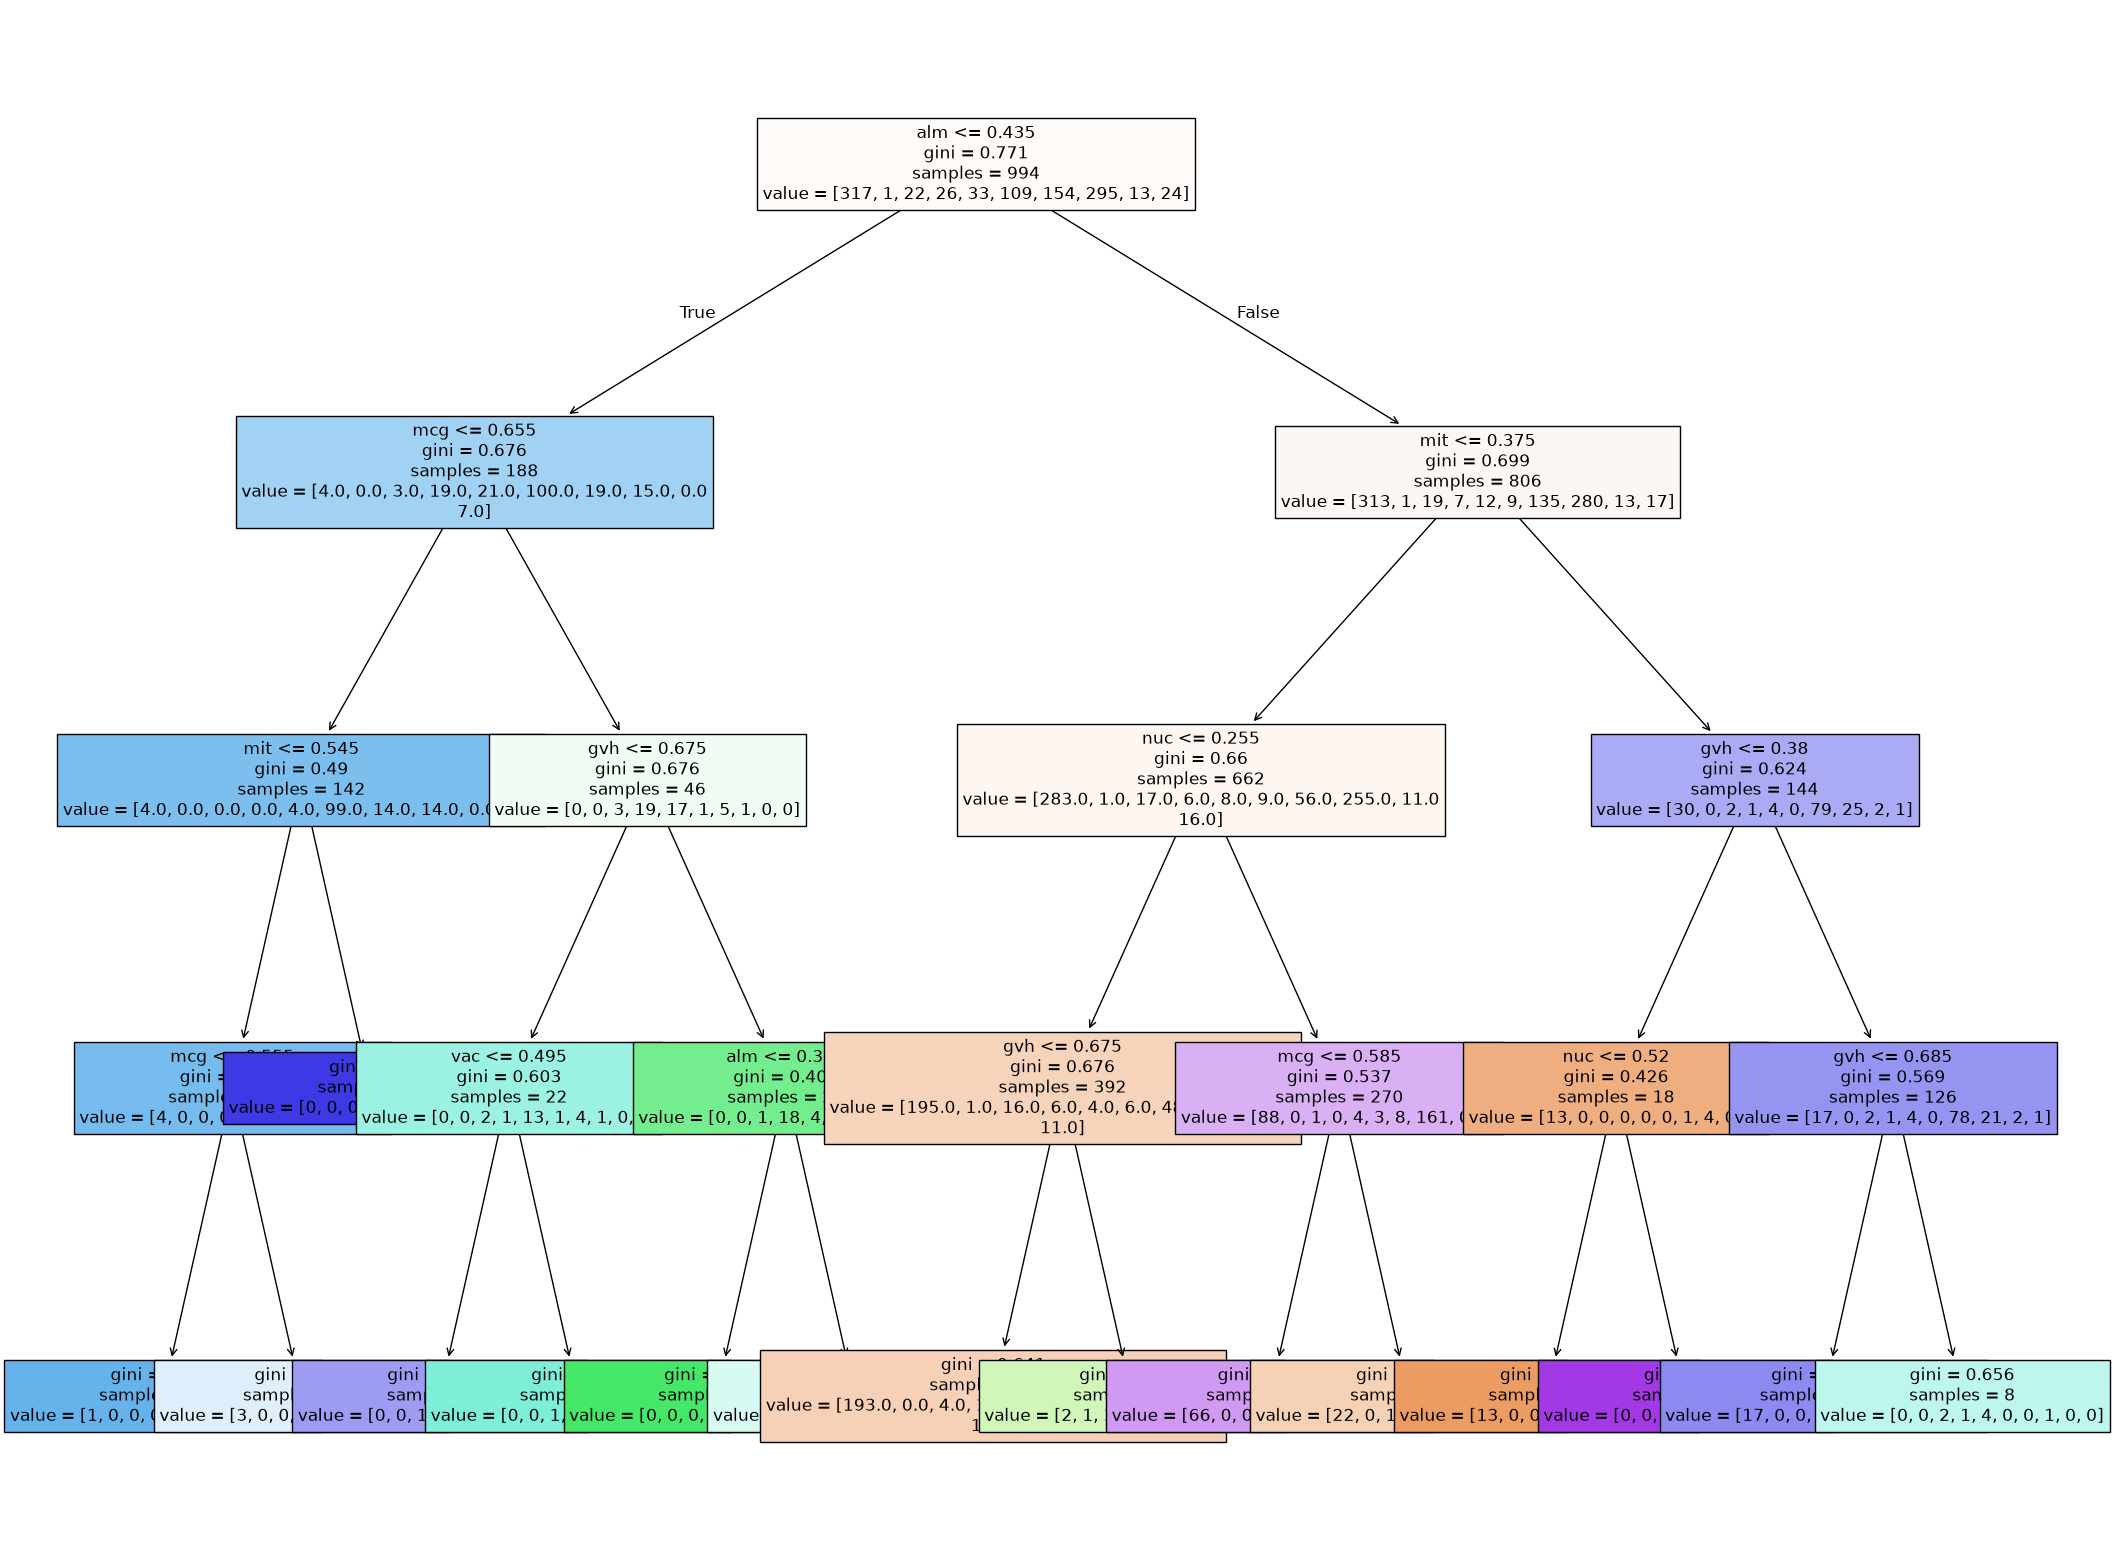

In [23]:
from sklearn import tree
from matplotlib import pyplot as plt

fig = plt.figure(figsize = (25,20))
_ = tree.plot_tree(clf,
                   feature_names = X_train.columns.tolist(),
                   filled=True,
                   fontsize=12)

In [34]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    recall_score,
    roc_auc_score
)

predictions = clf.predict(X_test)
probabilities = clf.predict_proba(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))
print("F1 Score:", f1_score(y_test, predictions, average="weighted"))
print("MCC:", matthews_corrcoef(y_test, predictions))
print("Recall:", recall_score(y_test, predictions, average="weighted"))
print(
    "AUC:",
    roc_auc_score(
        y_test,
        probabilities,
        labels=clf.classes_,
        multi_class="ovr",
        average="weighted"
    )
)

Accuracy: 0.5591836734693878
F1 Score: 0.548562288985506
MCC: 0.4366145347213172
Recall: 0.5591836734693878
AUC: 0.7768655822087069


In [32]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

scoring = {"f1": "f1_weighted",
    "recall": "recall_weighted",
    "mcc": "matthews_corrcoef",
    "auc": "roc_auc_ovr_weighted"}

cv_results = cross_validate(
    DecisionTreeClassifier(max_depth=4, random_state=42),
    X,
    y,
    cv=cv,
    scoring=scoring
)

for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean()}")

f1: 0.5353013159558866
recall: 0.5606674856674856
mcc: 0.4383529163974892
auc: 0.7727308634365923


In [27]:
scores

array([0.7817944 , 0.78460206, 0.74224969, 0.75336184, 0.80164633])